# Import and load data

In [1]:
from pathlib import Path
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from joblib import dump

SEED = 42
np.random.seed(SEED)

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'IE4483-sentiment-project-main']
ROOT = next((p for p in candidates if (p / 'data' / 'train.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot find data/train.json. Open this notebook from project/notebooks or project root.')
ROOT = ROOT.resolve()
print('Project directory:', ROOT)
train_df = pd.read_json(ROOT / 'data' / 'train.json')
test_df = pd.read_json(ROOT / 'data' / 'test.json')
print('Train:', train_df.shape, 'Test:', test_df.shape)
print('Class counts:', train_df['sentiments'].value_counts().to_dict())
assert set(train_df['sentiments'].unique()) == {0, 1}


Project directory: C:\Users\jayce\IE4483-sentiment-project-main
Train: (7401, 2) Test: (1851, 1)
Class counts: {1: 6319, 0: 1082}


## Note: Training set 7401 - 2 columns. Test set 1851, 1 column only

# 2. Reproduce existing split and TF-IDF settings

In [7]:
X_tr_text, X_va_text, y_tr, y_va = train_test_split(
    train_df['reviews'].fillna(''), train_df['sentiments'],
    test_size=0.2, random_state=SEED, stratify=train_df['sentiments'])
vectorizer = TfidfVectorizer(lowercase=True, stop_words='english',
                             ngram_range=(1,2), min_df=2, max_features=20000)
X_tr = vectorizer.fit_transform(X_tr_text)
X_va = vectorizer.transform(X_va_text)
print('TF-IDF train:', X_tr.shape, '| validation:', X_va.shape)


TF-IDF train: (5920, 20000) | validation: (1481, 20000)


## Understanding step 2:
Training rows - 5920 - reviews used to train SVM and MLP

Training columns - 20000. TF-IDF features used to represent each review

Validation rows - 1481 - reviews used to evaluate the models

Validation column - 20000. - Same TD-IDF features used during training

# 3. Model 1: SVM

In [17]:
svm = LinearSVC(C=1.0, class_weight='balanced', random_state=SEED, max_iter=5000)
t0 = time.perf_counter()
svm.fit(X_tr, y_tr)
svm_seconds = time.perf_counter() - t0
pred_svm = svm.predict(X_va)
print('SVM training time (s):', round(svm_seconds, 2))
print(classification_report(y_va, pred_svm, target_names=['negative','positive'], zero_division=0))

SVM training time (s): 0.11
              precision    recall  f1-score   support

    negative       0.80      0.71      0.76       217
    positive       0.95      0.97      0.96      1264

    accuracy                           0.93      1481
   macro avg       0.88      0.84      0.86      1481
weighted avg       0.93      0.93      0.93      1481



# 4. Model 2: two hidden layer MLP

In [20]:
n_components = min(200, X_tr.shape[0]-1, X_tr.shape[1]-1)
mlp = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(128,64), activation='relu', solver='adam',
                  alpha=0.001, learning_rate_init=0.001, batch_size=64,
                  early_stopping=True, validation_fraction=0.15, n_iter_no_change=10,
                  max_iter=150, random_state=SEED)
)
t0 = time.perf_counter()
mlp.fit(X_tr, y_tr)
mlp_seconds = time.perf_counter() - t0
pred_mlp = mlp.predict(X_va)
print('MLP training time (s):', round(mlp_seconds, 2))
print('Epochs used:', mlp.named_steps['mlpclassifier'].n_iter_)
print(classification_report(y_va, pred_mlp, target_names=['negative','positive'], zero_division=0))


MLP training time (s): 4.6
Epochs used: 17
              precision    recall  f1-score   support

    negative       0.74      0.60      0.67       217
    positive       0.93      0.96      0.95      1264

    accuracy                           0.91      1481
   macro avg       0.84      0.78      0.81      1481
weighted avg       0.91      0.91      0.91      1481



# 5. Compare using f1-score and accuracy score

,Model,Validation accuracy,Macro F1,Negative F1,Train seconds
0,Linear SVM,0.9325,0.8585,0.7561,0.1076
1,MLP (TF-IDF + SVD),0.9115,0.8078,0.6667,4.5988


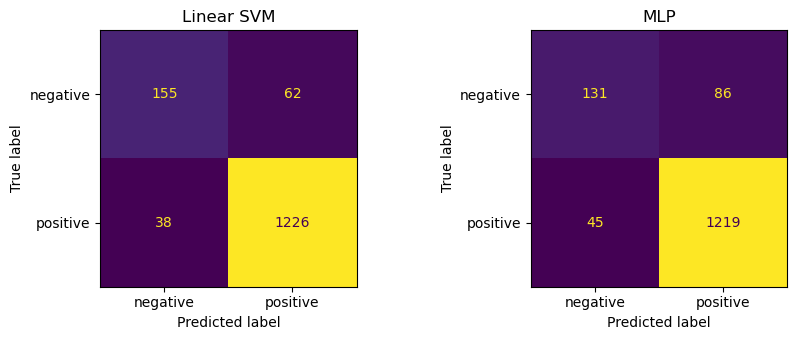

In [23]:
summary = pd.DataFrame([
    {'Model':'Linear SVM', 'Validation accuracy':accuracy_score(y_va,pred_svm),
     'Macro F1':f1_score(y_va,pred_svm,average='macro'),
     'Negative F1':f1_score(y_va,pred_svm,pos_label=0), 'Train seconds':svm_seconds},
    {'Model':'MLP (TF-IDF + SVD)', 'Validation accuracy':accuracy_score(y_va,pred_mlp),
     'Macro F1':f1_score(y_va,pred_mlp,average='macro'),
     'Negative F1':f1_score(y_va,pred_mlp,pos_label=0), 'Train seconds':mlp_seconds}
])
display(summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(9,3.5))
for ax, name, pred in zip(axes, ['Linear SVM','MLP'], [pred_svm,pred_mlp]):
    ConfusionMatrixDisplay.from_predictions(y_va, pred, labels=[0,1],
                                            display_labels=['negative','positive'], ax=ax,
                                            colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


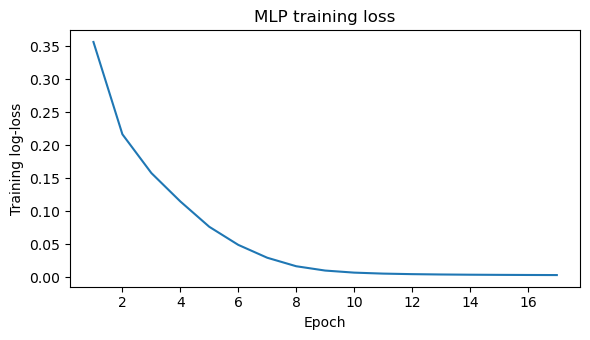

Saved to: C:\Users\jayce\IE4483-sentiment-project-main\results\part_b


In [25]:
history = mlp.named_steps['mlpclassifier'].loss_curve_
plt.figure(figsize=(6,3.5))
plt.plot(range(1,len(history)+1), history)
plt.xlabel('Epoch'); plt.ylabel('Training log-loss'); plt.title('MLP training loss')
plt.tight_layout(); plt.show()
out = ROOT / 'results' / 'part_b'
out.mkdir(parents=True, exist_ok=True)
summary.to_csv(out / 'svm_mlp_validation_metrics.csv', index=False)
with open(out / 'model_config.json', 'w', encoding='utf-8') as f:
    json.dump({'seed':SEED, 'split': 'stratified 80/20',
               'tfidf': {'lowercase':True,'stop_words':'english','ngram_range':[1,2],
                         'min_df':2,'max_features':20000},
               'svm': {'C':1.0,'class_weight':'balanced','max_iter':5000},
               'mlp':{'svd_features':n_components,'hidden_layers':[128,64],
                      'alpha':0.001,'learning_rate':0.001,'batch_size':64,
                      'early_stopping':True}}, f, indent=2)
dump({'vectorizer': vectorizer, 'svm':svm, 'mlp':mlp}, out / 'validation_models.joblib')
print('Saved to:', out)


### (b.1) Selection of Classification Models

Two classification models were selected for this project: Linear Support Vector Machine (SVM) and Multi-Layer Perceptron (MLP). Both models were implemented to classify product reviews into two sentiment categories, where 0 represents negative sentiment and 1 represents positive sentiment.

Linear SVM was chosen because it performs well with high-dimensional and sparse text features, such as those produced by Term Frequency-Inverse Document Frequency (TF-IDF). It identifies a decision boundary that separates the positive and negative sentiment classes while maximising the margin between them.

MLP was selected as a neural-network-based alternative. Unlike Linear SVM, which learns a linear decision boundary, MLP uses multiple layers of neurons and nonlinear activation functions to capture more complex relationships between features and sentiment labels.

By comparing these two models, the project aims to evaluate the effectiveness of traditional machine learning and neural network approaches for sentiment classification using the same TF-IDF representation.

### (b.2) Input Features and Data Preparation

The dataset contains 7,401 labelled product reviews, comprising 6,319 positive and 1,082 negative reviews.

The labelled dataset was divided into training and validation subsets using an 80:20 stratified split, resulting in 5,920 training samples and 1,481 validation samples. A random seed of 42 was used to ensure consistency.

The reviews were transformed into numerical features using TF-IDF with the following settings:

- Lowercase conversion enabled
- English stop-word removal
- Unigrams and bigrams
- Minimum document frequency of 2
- Maximum vocabulary size of 20,000

The TF-IDF vectorizer was fitted only on the training data before transforming the validation data. This prevents data leakage and ensures that both datasets use the same feature representation.

Each review was represented as a 20,000-dimensional TF-IDF feature vector.

### (b.3) Linear Support Vector Machine

Linear SVM was implemented using the `LinearSVC` classifier from Scikit-learn.

The model takes a 20,000-dimensional TF-IDF vector as input and produces a binary sentiment prediction.

Linear SVM identifies an optimal separating hyperplane between positive and negative reviews by maximising the classification margin while penalising classification errors.

The regularisation parameter was set to C = 1.0, and balanced class weights were applied to address the imbalance between positive and negative reviews.

The classifier uses squared hinge loss, which penalises incorrectly classified samples and samples that fall within the margin.

During training, the model learns a weight vector and bias term, which are subsequently used to classify unseen reviews.

### (b.4) Multi-Layer Perceptron

MLP was implemented using Scikit-learn's `MLPClassifier`.

Since TF-IDF produces a high-dimensional feature representation, Truncated Singular Value Decomposition (TruncatedSVD) was applied to reduce the feature dimension from 20,000 to 200. The reduced features were then standardised before being passed into the MLP.

The neural network consists of an input layer with 200 features, two hidden layers containing 128 and 64 neurons respectively, and an output layer with one neuron for binary sentiment classification.

The hidden layers use the Rectified Linear Unit (ReLU) activation function, which introduces nonlinearity and allows the model to learn more complex feature relationships. The output layer uses a logistic activation function to produce a probability between 0 and 1.

Binary cross-entropy was used as the loss function, while the Adam optimiser was employed to update the model weights.

The initial learning rate was set to 0.001, with a batch size of 64 and a maximum of 150 training iterations.

L2 regularisation with an alpha value of 0.001 was applied to reduce overfitting. Early stopping was enabled, using 15% of the MLP training input for internal validation and a patience of 10 iterations without sufficient improvement.

### (b.5) Training Strategy and Reproducibility

Both models were trained and evaluated using the same stratified training-validation split to ensure a fair comparison.

Linear SVM was trained directly using the TF-IDF features, while MLP used dimensionality-reduced and standardised TF-IDF features.

A fixed random seed of 42 was used during data splitting and model initialisation to improve reproducibility.

Model performance was evaluated using accuracy, precision, recall, F1-score and confusion matrices.

As the dataset contains significantly more positive reviews than negative reviews, macro F1-score was considered alongside accuracy to provide a more balanced evaluation of classification performance.

The separate test dataset containing 1,851 unlabelled reviews was reserved for final sentiment prediction.

### (b.6) Classification Results and Discussion

The experimental results showed that Linear SVM achieved stronger classification performance than MLP.

| Evaluation Metric | Linear SVM | MLP |
|---|---:|---:|
| Validation Accuracy | 93.18% | 91.36% |
| Macro F1-score | 0.8567 | 0.8181 |
| Negative-class F1-score | 0.7531 | 0.6863 |

Linear SVM achieved a higher validation accuracy of 93.18%, compared with 91.36% for MLP. It also obtained a higher macro F1-score, indicating better overall performance across both sentiment classes.

The stronger results of Linear SVM suggest that the TF-IDF features provide a representation that can be effectively separated using a linear decision boundary.

Although MLP has the ability to model nonlinear relationships, its performance may be affected by the additional complexity of the neural network and the dimensionality reduction applied before training.

Overall, Linear SVM was selected as the better-performing classifier based on the validation results.